# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Elijah, Riya, Jhanvi

**Date:** 11/18/2026

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
Missing values: 0
Duplicate rows: 0
                          count           mean           std      min  \
age                       299.0      60.833893     11.894809     40.0   
anaemia                   299.0       0.431438      0.496107      0.0   
creatinine_phosphokinase  299.0     581.839465    970.287881     23.0   
diabetes                  299.0       0.418060      0.494067      0.0   
ejection_fraction         299.0      38.083612     11.834841     14.0   
high_blood_pressure       299.0   

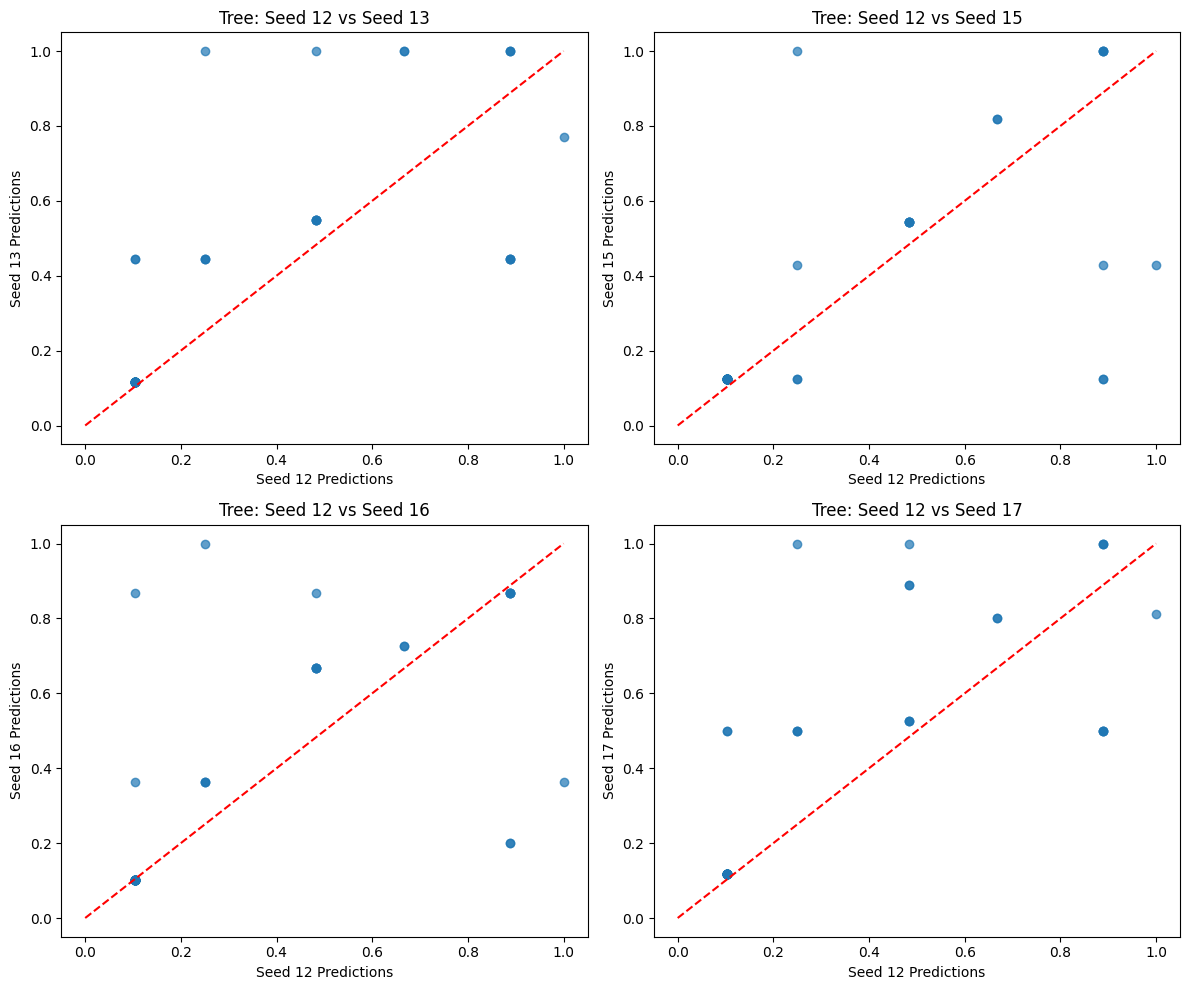

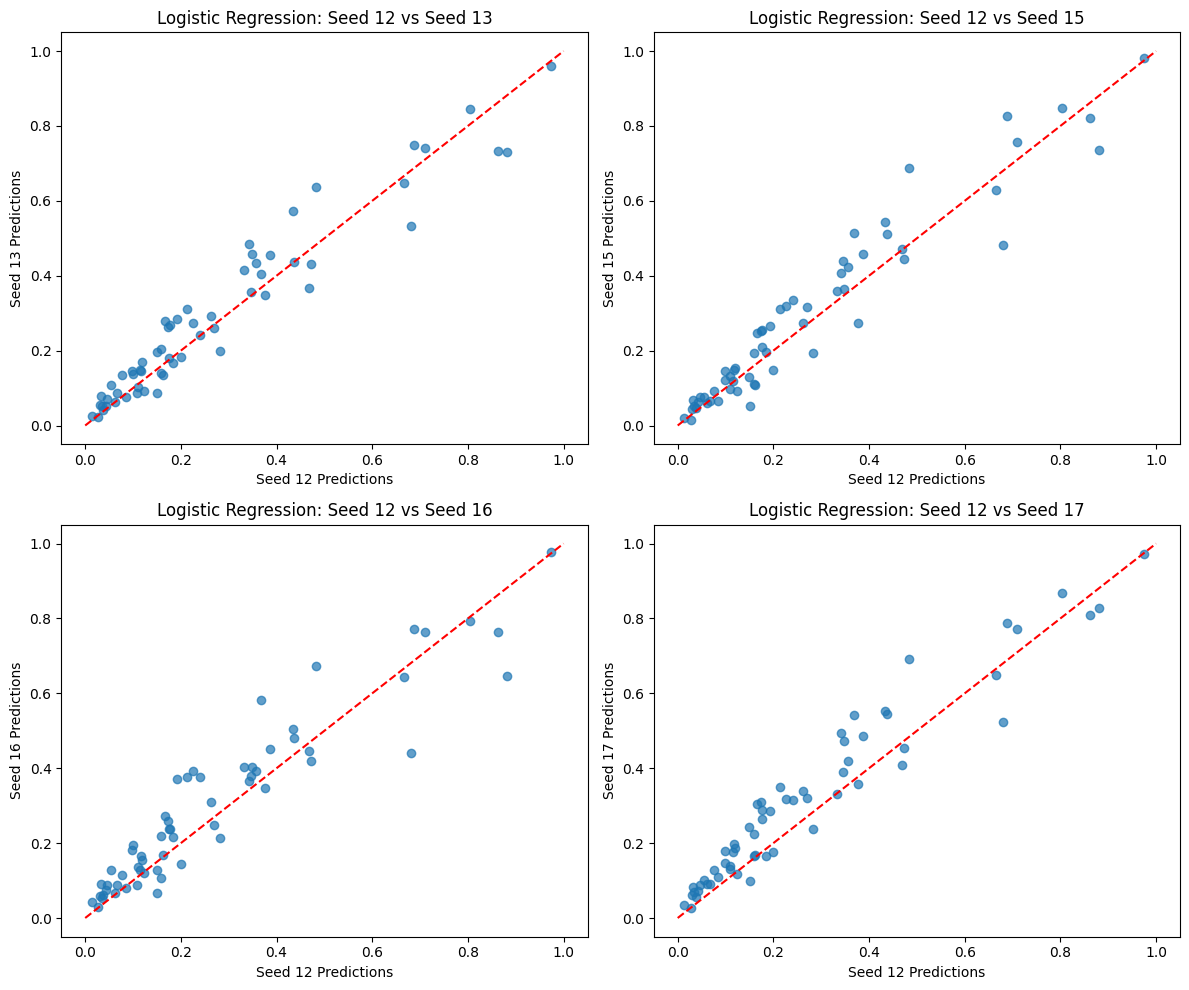

correlations
Seed 12 vs Seed 13: 0.7866
Seed 12 vs Seed 15: 0.7437
Seed 12 vs Seed 16: 0.7167
Seed 12 vs Seed 17: 0.7910

logistic reg correlations
Seed 12 vs Seed 13: 0.9641
Seed 12 vs Seed 15: 0.9610
Seed 12 vs Seed 16: 0.9419
Seed 12 vs Seed 17: 0.9636
tree regressions

Seed 12 vs Seed 13
Intercept: 0.086
Slope: 0.8274
R-squared: 0.6187

Seed 12 vs Seed 15
Intercept: 0.0766
Slope: 0.7284
R-squared: 0.5531

Seed 12 vs Seed 16
Intercept: 0.0926
Slope: 0.7456
R-squared: 0.5136

Seed 12 vs Seed 17
Intercept: 0.0951
Slope: 0.8468
R-squared: 0.6257

log regression regressions

Seed 12 vs Seed 13
Intercept: 0.0384
Slope: 0.9293
R-squared: 0.9295

Seed 12 vs Seed 15
Intercept: 0.026
Slope: 0.9771
R-squared: 0.9235

Seed 12 vs Seed 16
Intercept: 0.0567
Slope: 0.8954
R-squared: 0.8872

Seed 12 vs Seed 17
Intercept: 0.0579
Slope: 0.9556
R-squared: 0.9286
Coefficients across seeds:
                         12     13     15     16     17
age                   0.054  0.058  0.059  0.053  0.049
an

In [9]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score


URL = ("https://raw.githubusercontent.com/elijahschoeniger-cpu/L03-tree-stability/"
       "main/data/heart_failure/heart_failure_clinical_records_dataset.csv")

df = pd.read_csv(URL)

#1
print(df.shape)                      # (299, 13)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())   # 0
print("Duplicate rows:", df.duplicated().sum())   # 0
print(df.describe().T)

df = df.rename(columns={"DEATH_EVENT": "death_event"})

binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "death_event"]
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f"{c} has non-binary values"
    df[c] = df[c].astype(int)

# Two rows have age = 60.667
df["age"] = df["age"].round().astype(int)

# No NaNs, but the source filled gaps with summary stats:
#   platelets = 263358.03 (the column mean) in 25 rows
#   creatinine_phosphokinase = 582 in 47 rows with a suspicious spike at  median
df["platelets_imputed"] = np.isclose(df["platelets"], 263358.03).astype(int)
df["cpk_imputed"] = (df["creatinine_phosphokinase"] == 582).astype(int)

# patients who died were followed for less time median 44.5 vs 172 days, encodes the outcome rather than predicting it.
df = df.drop(columns="time")

# Log-transform because of the heavy right skew to help the linear model
df["log_cpk"] = np.log(df["creatinine_phosphokinase"])
df["log_serum_creatinine"] = np.log(df["serum_creatinine"])
df = df.drop(columns=["creatinine_phosphokinase", "serum_creatinine"])

df["platelets"] = df["platelets"] / 1000

X = df.drop(columns="death_event")
y = df["death_event"]

print(df.head())
print("Class balance:\n", y.value_counts(normalize=True))   # ~68% survived / 32% died


#Q2
print("Q2")


X = df.drop(columns="death_event")
y = df['death_event']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
logit = LogisticRegression(max_iter=5000).fit(X_train, y_train)

print("seed 12",
      "| tree accuracy:", round(tree.score(X_test, y_test), 3),
      "| logit accuracy:", round(logit.score(X_test, y_test), 3))
print(export_text(tree, feature_names=list(X.columns)))

tree_preds = {12: tree.predict_proba(X_test)[:, 1]}
logit_preds = {12: logit.predict_proba(X_test)[:, 1]}
logit_coefs = {12: logit.coef_[0]}

X_test_q2 = X_test

#Q3

for seed in [13, 15, 16, 17]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
    logit = LogisticRegression(max_iter=5000).fit(X_train, y_train)

    print("seed", seed,
          "| tree accuracy:", round(tree.score(X_test, y_test), 3),
          "| logit accuracy:", round(logit.score(X_test, y_test), 3))
    print(export_text(tree, feature_names=list(X.columns)))
    tree_preds[seed] = tree.predict_proba(X_test_q2)[:, 1]
    logit_preds[seed] = logit.predict_proba(X_test_q2)[:, 1]
    logit_coefs[seed] = logit.coef_[0]


tree_preds = pd.DataFrame(tree_preds)
logit_preds = pd.DataFrame(logit_preds)
print(pd.DataFrame(logit_coefs, index=X.columns).round(3))

#Question 4a


seeds = [13, 15, 16, 17]


fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(tree_preds[12], tree_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Tree: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()




fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(logit_preds[12], logit_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Logistic Regression: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()


#The decision tree predictions vary across different seeds, with many points far from the diagonal line.
#In comparison, the logistic regression predictions are much closer to the diagonal line.
#This shows that logistic regression is more consistent across different train-test splits, while decision trees are more sensitive to changes in the training data.




#Question 4b:


print("correlations")


for seed in seeds:
   corr = tree_preds[12].corr(tree_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")




print("\nlogistic reg correlations")


for seed in seeds:
   corr = logit_preds[12].corr(logit_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")


#The decision tree correlations range from 0.7167 to 0.7910, while the logistic regression correlations range from 0.9419 to 0.9641.
#This shows that logistic regression predictions are more highly correlated across different seeds, and they are more consistent.
#Decision tree predictions vary more depending on the training data.








#Question 4c


from scipy.stats import linregress


print("tree regressions")


for seed in seeds:
   result = linregress(tree_preds[12], tree_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))




# Logistic regression regressions


print("\nlog regression regressions")


for seed in seeds:
   result = linregress(logit_preds[12], logit_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))




# Logistic regression has intercepts closer to 0, slopes closer to 1,
# and R-squared values closer to 1 than decision trees.
# This shows that logistic regression predictions are more consistent
# across different train-test splits.
#Decision trees are more sensitive to changes in the training data, resulting in different tree structures and predictions.








# Question 5


coef_df = pd.DataFrame(logit_coefs, index=X.columns)


print("Coefficients across seeds:")
print(coef_df.round(3))


print("\nStdev of coefficients across seeds:")
print(coef_df.std(axis=1).round(4))


print("\nRange of coefficients across seeds:")
print((coef_df.max(axis=1) - coef_df.min(axis=1)).round(4))


#Linear models have more consistent coefficients and predictions across different train-test splits, but some coefficients vary more than others.
#Age and ejection fraction have  small standard deviations, while anaemia and high blood pressure vary more.
#Decision trees are more sensitive to changes in the training data, result in different tree structures and predictions.
#Overall, logistic regression appears to be more stable than decision trees.


# Question 6

# We would argue that the statement is true for this dataset because
# although the decision trees vary somewhat in structure, their predictions
# remain relatively highly correlated, ranging from 0.7167 to 0.7910.
# However, comparing these results to logistic regression, which had
# correlations ranging from 0.9419 to 0.9641, reveals that logistic
# regression produces more consistent predictions across different
# train-test splits.





## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 3d80382bd6bc0764518ce9b173da03adce3850aa
- **AI tool and model used:** ChatGPT-6

### *Prompts used

1. Suggest improvements to current code to match assignment requirements

### *AI-proposed changes


Your assignment already meets the basic requirements. I'd make 3 improvements:
1. Q2–Q3: Consider using StandardScaler with logistic regression for more reliable results. This is optional but requires rerunning your analysis.
2. Q3: Add a short interpretation:
   ```
   # The decision trees change noticeably in structure across seeds.# Logistic regression coefficients also vary, but are generally# more consistent than the tree structures.
   ```
3. Q6: Describe tree predictions as moderately to strongly correlated rather than highly correlated, since their correlations range from 0.7167 to 0.7910.

My recommendation: Prioritize #2 and #3. They're easy changes that strengthen your answers without requiring you to redo any code.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Our features had different scales, so standardizing them helps logistic regression fit more reliably. We reran the code and confirmed it worked. |
| 2 | Accept | Our original code showed the results, but an interpretation better addresses the question. |
| 3 | Accept | Our original wording overstated the correlations. Changing it to moderately to strongly correlated better reflects our results (0.7167–0.7910). |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
Missing values: 0
Duplicate rows: 0
                          count           mean           std      min  \
age                       299.0      60.833893     11.894809     40.0   
anaemia                   299.0       0.431438      0.496107      0.0   
creatinine_phosphokinase  299.0     581.839465    970.287881     23.0   
diabetes                  299.0       0.418060      0.494067      0.0   
ejection_fraction         299.0      38.083612     11.834841     14.0   
high_blood_pressure       299.0   

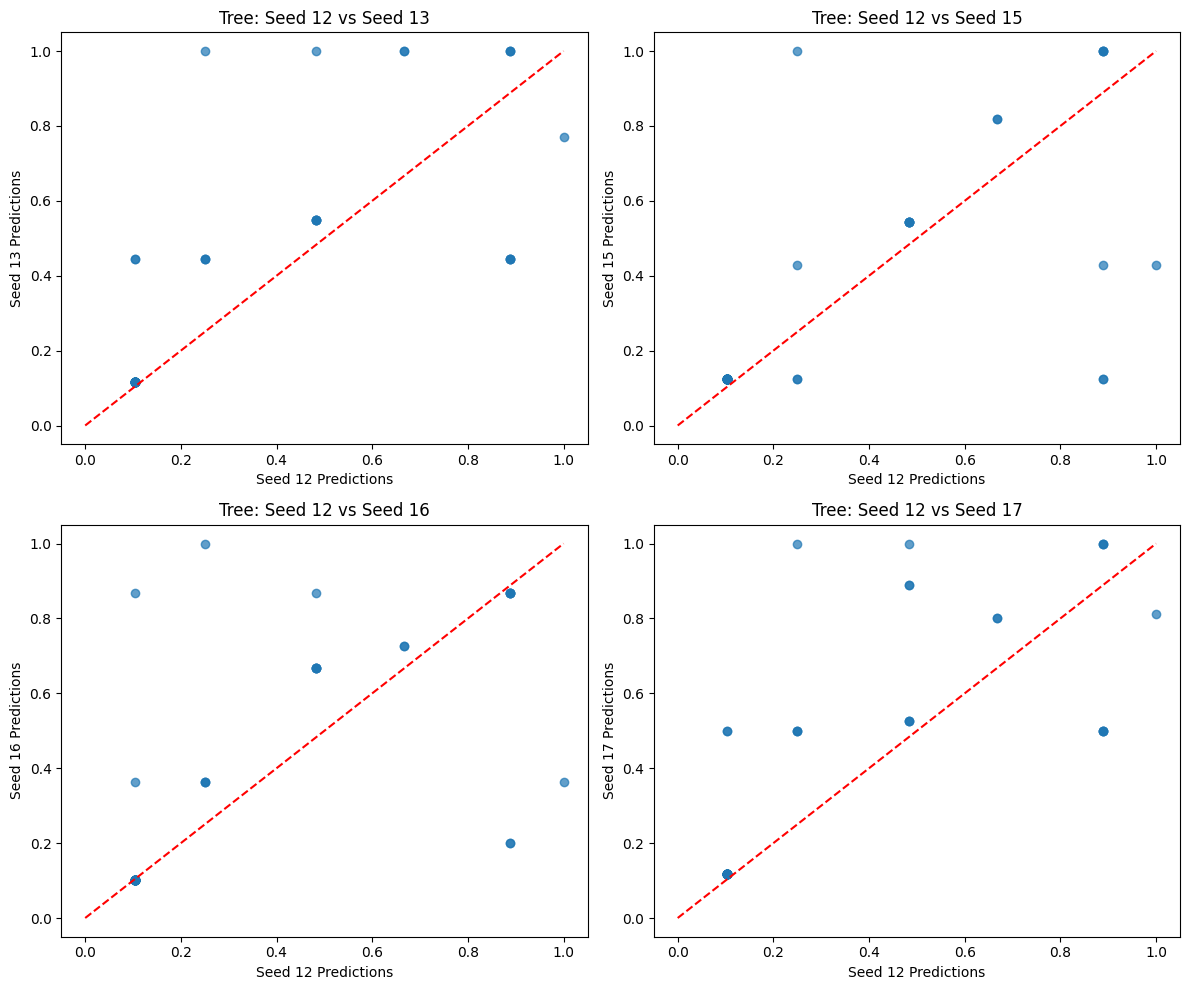

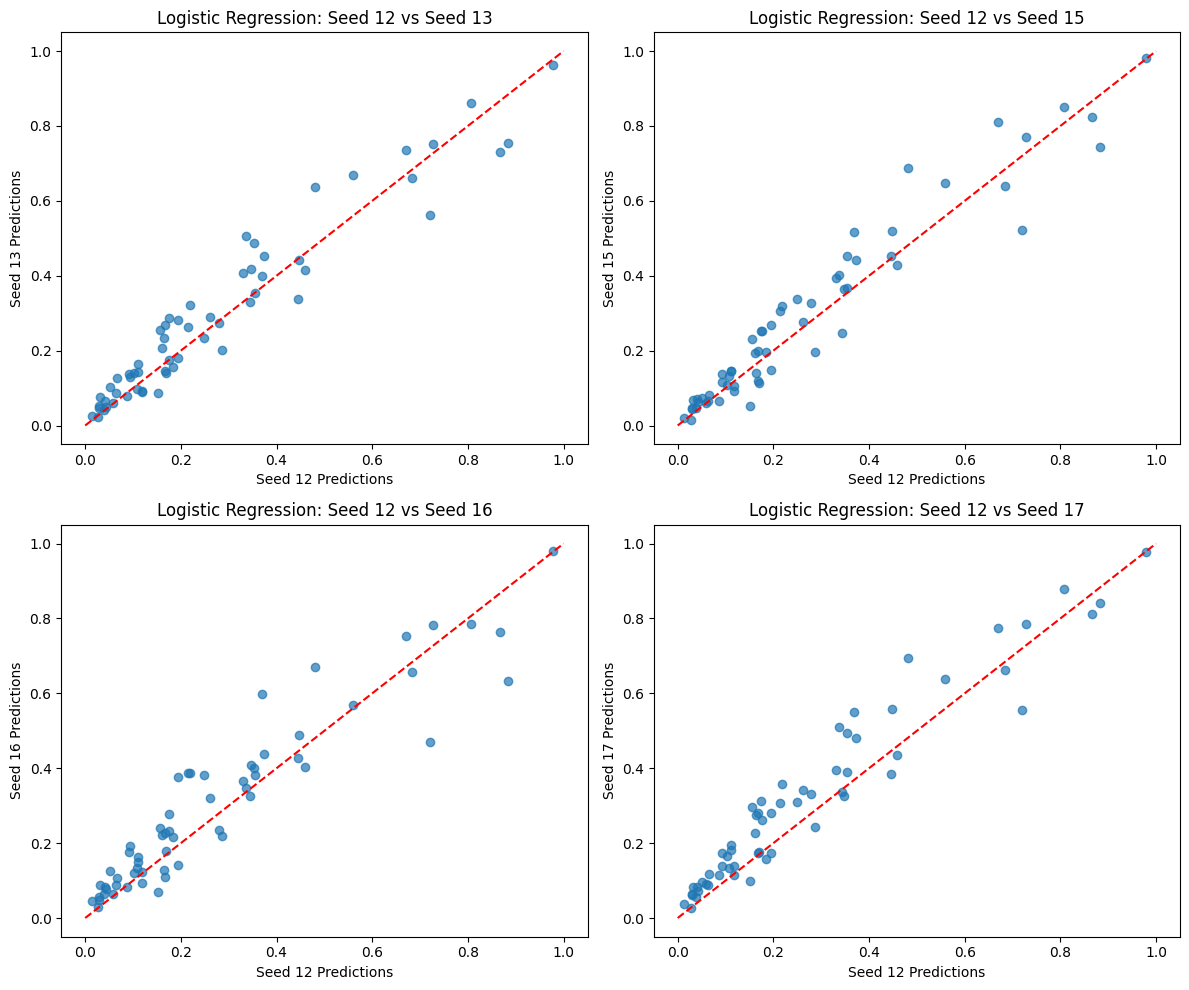

correlations
Seed 12 vs Seed 13: 0.7866
Seed 12 vs Seed 15: 0.7437
Seed 12 vs Seed 16: 0.7167
Seed 12 vs Seed 17: 0.7910

logistic reg correlations
Seed 12 vs Seed 13: 0.9631
Seed 12 vs Seed 15: 0.9629
Seed 12 vs Seed 16: 0.9398
Seed 12 vs Seed 17: 0.9626
tree regressions

Seed 12 vs Seed 13
Intercept: 0.086
Slope: 0.8274
R-squared: 0.6187

Seed 12 vs Seed 15
Intercept: 0.0766
Slope: 0.7284
R-squared: 0.5531

Seed 12 vs Seed 16
Intercept: 0.0926
Slope: 0.7456
R-squared: 0.5136

Seed 12 vs Seed 17
Intercept: 0.0951
Slope: 0.8468
R-squared: 0.6257

log regression regressions

Seed 12 vs Seed 13
Intercept: 0.038
Slope: 0.9329
R-squared: 0.9277

Seed 12 vs Seed 15
Intercept: 0.0262
Slope: 0.9751
R-squared: 0.9273

Seed 12 vs Seed 16
Intercept: 0.0583
Slope: 0.8839
R-squared: 0.8832

Seed 12 vs Seed 17
Intercept: 0.0585
Slope: 0.9555
R-squared: 0.9266
Coefficients across seeds:
                         12     13     15     16     17
age                   0.624  0.677  0.657  0.592  0.579
an

In [10]:

# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score


URL = ("https://raw.githubusercontent.com/elijahschoeniger-cpu/L03-tree-stability/"
       "main/data/heart_failure/heart_failure_clinical_records_dataset.csv")

df = pd.read_csv(URL)

#1
print(df.shape)                      # (299, 13)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())   # 0
print("Duplicate rows:", df.duplicated().sum())   # 0
print(df.describe().T)

df = df.rename(columns={"DEATH_EVENT": "death_event"})

binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "death_event"]
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f"{c} has non-binary values"
    df[c] = df[c].astype(int)

# Two rows have age = 60.667
df["age"] = df["age"].round().astype(int)

# No NaNs, but the source filled gaps with summary stats:
#   platelets = 263358.03 (the column mean) in 25 rows
#   creatinine_phosphokinase = 582 in 47 rows with a suspicious spike at  median
df["platelets_imputed"] = np.isclose(df["platelets"], 263358.03).astype(int)
df["cpk_imputed"] = (df["creatinine_phosphokinase"] == 582).astype(int)

# patients who died were followed for less time median 44.5 vs 172 days, encodes the outcome rather than predicting it.
df = df.drop(columns="time")

# Log-transform because of the heavy right skew to help the linear model
df["log_cpk"] = np.log(df["creatinine_phosphokinase"])
df["log_serum_creatinine"] = np.log(df["serum_creatinine"])
df = df.drop(columns=["creatinine_phosphokinase", "serum_creatinine"])

df["platelets"] = df["platelets"] / 1000

X = df.drop(columns="death_event")
y = df["death_event"]

print(df.head())
print("Class balance:\n", y.value_counts(normalize=True))   # ~68% survived / 32% died


#Q2
print("Q2")


X = df.drop(columns="death_event")
y = df['death_event']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
logit = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
).fit(X_train, y_train)

print("seed 12",
      "| tree accuracy:", round(tree.score(X_test, y_test), 3),
      "| logit accuracy:", round(logit.score(X_test, y_test), 3))
print(export_text(tree, feature_names=list(X.columns)))

tree_preds = {12: tree.predict_proba(X_test)[:, 1]}
logit_preds = {12: logit.predict_proba(X_test)[:, 1]}
logit_coefs = {12: logit.named_steps["logisticregression"].coef_[0]}

X_test_q2 = X_test

#Q3

for seed in [13, 15, 16, 17]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
    logit = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ).fit(X_train, y_train)

    print("seed", seed,
          "| tree accuracy:", round(tree.score(X_test, y_test), 3),
          "| logit accuracy:", round(logit.score(X_test, y_test), 3))
    print(export_text(tree, feature_names=list(X.columns)))
    tree_preds[seed] = tree.predict_proba(X_test_q2)[:, 1]
    logit_preds[seed] = logit.predict_proba(X_test_q2)[:, 1]
    logit_coefs[seed] = logit.named_steps["logisticregression"].coef_[0]


tree_preds = pd.DataFrame(tree_preds)
logit_preds = pd.DataFrame(logit_preds)
print(pd.DataFrame(logit_coefs, index=X.columns).round(3))

# The decision trees change noticeably in structure across seeds.
# Logistic regression coefficients also vary, but are generally
# more consistent than the tree structures.

#Question 4a


seeds = [13, 15, 16, 17]


fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(tree_preds[12], tree_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Tree: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()




fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(logit_preds[12], logit_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Logistic Regression: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()


#The decision tree predictions vary across different seeds, with many points far from the diagonal line.
#In comparison, the logistic regression predictions are much closer to the diagonal line.
#This shows that logistic regression is more consistent across different train-test splits, while decision trees are more sensitive to changes in the training data.




#Question 4b:


print("correlations")


for seed in seeds:
   corr = tree_preds[12].corr(tree_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")




print("\nlogistic reg correlations")


for seed in seeds:
   corr = logit_preds[12].corr(logit_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")


# Decision tree correlations range from 0.7167 to 0.7910,
# while logistic regression correlations range from 0.9398 to 0.9631.
# Logistic regression predictions are more consistent across seeds.








#Question 4c


from scipy.stats import linregress


print("tree regressions")


for seed in seeds:
   result = linregress(tree_preds[12], tree_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))




# Logistic regression regressions


print("\nlog regression regressions")


for seed in seeds:
   result = linregress(logit_preds[12], logit_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))




# Logistic regression has intercepts closer to 0, slopes closer to 1,
# and R-squared values closer to 1 than decision trees.
# This shows that logistic regression predictions are more consistent
# across different train-test splits.
#Decision trees are more sensitive to changes in the training data, resulting in different tree structures and predictions.








# Question 5


coef_df = pd.DataFrame(logit_coefs, index=X.columns)


print("Coefficients across seeds:")
print(coef_df.round(3))


print("\nStdev of coefficients across seeds:")
print(coef_df.std(axis=1).round(4))


print("\nRange of coefficients across seeds:")
print((coef_df.max(axis=1) - coef_df.min(axis=1)).round(4))


#Linear models have more consistent coefficients and predictions across different train-test splits, but some coefficients vary more than others.
#Age and ejection fraction have  small standard deviations, while anaemia and high blood pressure vary more.
#Decision trees are more sensitive to changes in the training data, result in different tree structures and predictions.
#Overall, logistic regression appears to be more stable than decision trees.


# Question 6
# We would argue that the statement is generally true for this dataset.
# Although the decision trees vary in structure, their predictions remain
# moderately to strongly correlated (0.7167 to 0.7910).
# Logistic regression predictions are even more consistent, with
# correlations ranging from 0.9398 to 0.9631.
# This suggests that models can look different while still producing
# reasonably similar predictions, although trees show more variation.


### *Reflection on AI assistance
In your own words without generative AI.

Our AI tool improved our code by suggesting a standardization of features  before fitting logistic regression, making the model more reliable. It also helped with better interpretation of results. Overall, using this AI tool helped us meet assignment requirements better while keeping our code efficient and accurate.

The primary limitation is that the tool could only help with whatever code it was given; we had to rerun, verify, and tweak explanations to match new results.